<a href="https://colab.research.google.com/github/HamzaEric/online_retail_data_analytics/blob/main/Notebooks/exploring_sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [4]:
path_2009_2010 = "/content/drive/MyDrive/online_retail_data/online-retail-2009-2010.csv/online-retail-2009-2010.csv"
path_2010_2011 = "/content/drive/MyDrive/online_retail_data/online-retail-2010-2011.csv/online-retail-2010-2011.csv"

df_1 = pd.read_csv(path_2009_2010, parse_dates=["InvoiceDate"])
df_2 = pd.read_csv(path_2010_2011,  parse_dates=["InvoiceDate"])

In [5]:
df_1.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [6]:
df_2.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [9]:
print(df_1.dtypes)
print(df_1.shape)
print("=" * 55)
print(df_2.dtypes)
print(df_2.shape)

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object
(525461, 8)
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object
(541910, 8)


> Concat the Datasets

In [11]:
df = pd.concat([df_1, df_2], ignore_index=True)
print(df.shape)
print(df["InvoiceDate"].min(), "->" ,df["InvoiceDate"].max())

(1067371, 8)
2009-12-01 07:45:00 -> 2011-12-09 12:50:00


## Revenue

The manager's first question is the simplest one: *how much did we sell, month by month?*
Each line's value is its **revenue**: quantity × price — a derived feature.

In [12]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')

In [13]:
df['Revenue'] = df["Quantity"] * df["Price"]

df[["Quantity","Price","Revenue"]].head(3)

,Quantity,Price,Revenue
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0


In [14]:
monthly_revenue = df.set_index("InvoiceDate")["Revenue"].resample("ME").sum()
print(len(monthly_revenue), "months")
(monthly_revenue / 1000).round(0).tail(3)

25 months


,Revenue
InvoiceDate,
2011-10-31,1071.0
2011-11-30,1462.0
2011-12-31,434.0


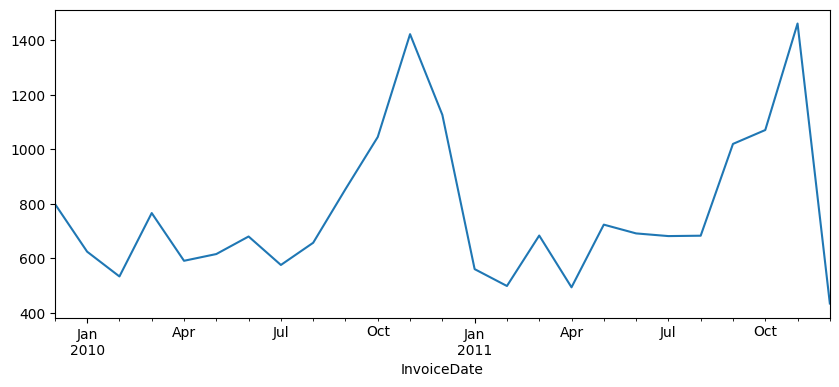

In [18]:
monthly_plot = (monthly_revenue / 1000).plot(kind="line", figsize=(10,4))
plt.show()

> **Reading the chart.** The big shape is clear: sales climb every autumn and **peak in
> November** — Christmas stock for the shop's customers — then drop in January. But two
> details look wrong once you know the calendar:
>
> 1. **December 2010** (about `£1.13M`) stays close to November 2010, although a gift shop's
>    customers have mostly bought their Christmas stock by December — the first December in
>    the data, 2009, sits at about `£0.80M`. Why would December 2010 be so strong?
> 2. **December 2011** falls off a cliff, to about `£0.43M` — the lowest month in two years,
>    right after the highest.
>
> Neither is an error message. Both are questions.

> **Key insight — a chart is a data-quality tool.** A million rows hide a problem; one line
> across 25 months shows it. Before you present a chart, *interrogate* it: every surprising
> point is either a finding about the world or a problem in the data — and you must know which.

## Investigate Data Overlap Skepticism

Start with the December 2010 bump. The two files came from two sheets, one per year of
trading. What if the years overlap? The last date of the first file and the first date of the
second answer that in two lines.

In [19]:
print("first file ends:   ", df_1["InvoiceDate"].max())
print("second file starts:", df_2["InvoiceDate"].min())

first file ends:    2010-12-09 20:01:00
second file starts: 2010-12-01 08:26:00


In [20]:
in_first = (df_1["InvoiceDate"] >= "2010-12-01").sum()
in_second = (df_2["InvoiceDate"] < "2010-12-10").sum()
print(f"lines of 1-9 Dec 2010 in the first file: {in_first:,}   in the second: {in_second:,}")
n_identical = df.duplicated().sum()
print(f"identical lines in the stacked table:    {n_identical:,}")
print(f"  explained by the overlap:              {in_second:,}")
print(f"  repeated within one file:              {n_identical - in_second:,}")

lines of 1-9 Dec 2010 in the first file: 22,523   in the second: 22,523
identical lines in the stacked table:    34,335
  explained by the overlap:              22,523
  repeated within one file:              11,812


> 📊 **Reading the overlap.** The first sheet runs until **9 December 2010**, but the second
> starts on **1 December 2010**: both contain the same nine days — **22,523** lines each. When
> we stacked them, those days were counted **twice**, which is exactly why December 2010 looked
> so strong. In total, `.duplicated()` (recall Lesson 2.3) finds **34,335** lines that are exact
> copies of an earlier line, and they have **two different causes**: **22,523** are the
> overlap's second copies, and the other **11,812** are lines repeated *within* one file (same
> invoice, product, quantity, price and minute). Lesson 4.3 will look at the second group
> separately and document the decision.

In [23]:
df = df.drop_duplicates()

print(f"{len(df):,} lines")

1,033,036 lines


In [24]:
monthly_revenue = df.set_index("InvoiceDate")["Revenue"].resample("ME").sum()

print("last line in the data:", df["InvoiceDate"].max())
(monthly_revenue[monthly_revenue.index.month.isin([11, 12])] / 1000).round(0)

last line in the data: 2011-12-09 12:50:00


,Revenue
InvoiceDate,
2009-12-31,797.0
2010-11-30,1417.0
2010-12-31,747.0
2011-11-30,1456.0
2011-12-31,433.0


> 📊 **Reading the Decembers.** December 2010 drops from about `£1.13M` to **`£747k`** once
> the duplicates are removed — now it follows November (`£1.42M`) down, like every other December. And
> December 2011 (`£433k`) is not a collapse: the data simply **stops on 9 December 2011** at
> 12:50. It is a partial month — nine days compared with full months.

> ⚠️ **Common mistake — reading the last point of a time series as news.** The final month of
> almost any data extract is incomplete: the export was made mid-month. Always check the last
> date before reading the last point, and mark partial periods on any chart you show.

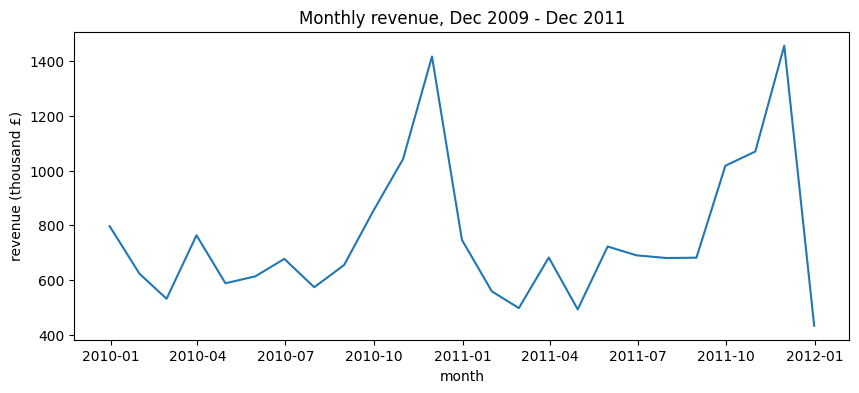

In [25]:
fig_month, ax_month = plt.subplots(figsize=(10, 4))

ax_month.plot(monthly_revenue.index, monthly_revenue.values / 1000)
ax_month.set_title("Monthly revenue, Dec 2009 - Dec 2011")
ax_month.set_xlabel("month")
ax_month.set_ylabel("revenue (thousand £)")
plt.show()

## Day Of The Week InvoiceDate Lines

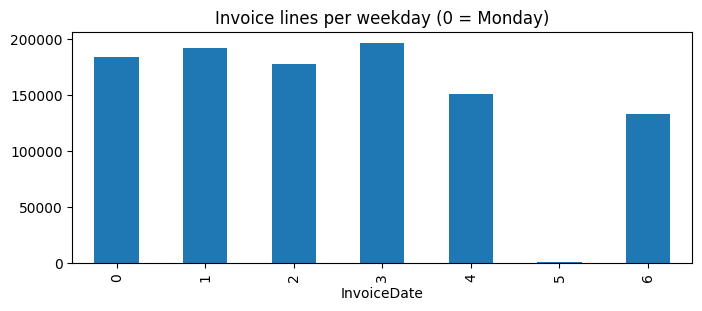

,count
InvoiceDate,
0,183699
1,191972
2,177445
3,196189
4,150312
5,402
6,133017


In [26]:
weekday_lines = df["InvoiceDate"].dt.dayofweek.value_counts().sort_index()

ax_week = weekday_lines.plot(kind="bar", figsize=(8, 3), title="Invoice lines per weekday (0 = Monday)")
plt.show()
weekday_lines

> 📊 **Reading the bars.** Monday to Thursday are busy (about 177,000–196,000 lines each),
> Friday a little quieter, Sunday active (133,017) — and **Saturday almost empty: 402 lines**.
> A question for the shop rather than an error: does it simply not process orders on
> Saturdays? Either way, a
> "busiest day" chart for the manager must not make Saturday look like a failure.

## Invoice Lines By Hour Of Day

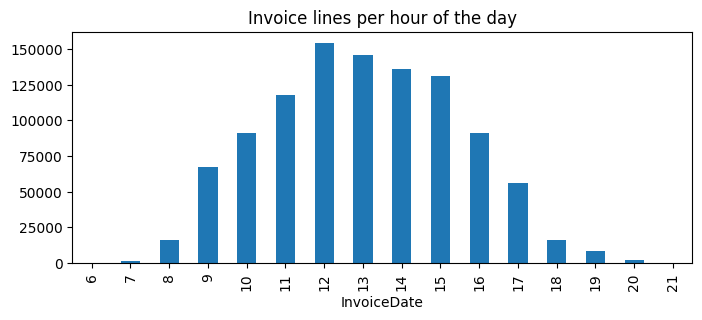

In [27]:
hour_lines = df["InvoiceDate"].dt.hour.value_counts().sort_index()

hour_lines.plot(kind="bar", figsize=(8, 3), title="Invoice lines per hour of the day")
plt.show()

> 📊 **Reading the hours.** Almost all orders are placed from 7:00 to about 21:00 (the bars at
> 6 and 21 are too small to see), rising through the
> morning to a peak at **12:00** and fading after 15:00 — a business-hours pattern, what you
> would expect from shops buying stock during their working day.

## Size Of Typical Order

40,078 orders   min £0.19   median £302.22   mean £510.92   max £168,469.60


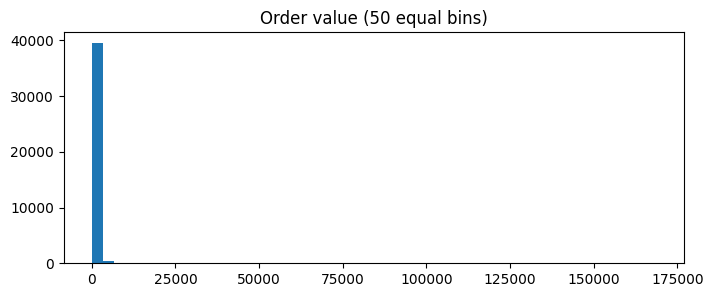

orders in the first bin (up to £3,370): 39,468 of 40,078 (98.5%)


In [29]:
invoice_value = df.groupby("Invoice")["Revenue"].sum()
orders = invoice_value[invoice_value > 0]
print(f"{len(orders):,} orders   min £{orders.min():.2f}   median £{orders.median():.2f}   mean £{orders.mean():.2f}   max £{orders.max():,.2f}")

fig, ax = plt.subplots(figsize=(8, 3))
counts, edges, bars = ax.hist(orders, bins=50)
ax.set_title("Order value (50 equal bins)")
plt.show()
print(f"orders in the first bin (up to £{edges[1]:,.0f}): {counts[0]:,.0f} of {len(orders):,} ({counts[0] / len(orders):.1%})")

> 📊 **Reading the histogram.** Almost useless — and that is the lesson. **40,078** orders,
> median **`£302`**, mean **`£511`**, but the biggest order is **`£168,470`**. To make room for
> it, the bins must be wide: the first one runs up to about `£3,370`, so it swallows
> **39,468 orders — 98.5 %** — and everything else is invisible. When values span from `£0.19`
> to six figures, equal-width bins hide the shape.

A **logarithmic scale** fixes it: instead of equal *steps* (0, 1,000, 2,000, …), the axis uses
equal *ratios* (1, 10, 100, 1,000, …), so small and large orders both get room.
`np.logspace(0, 6, 60)` makes 60 bin edges spread evenly on that scale, from 10⁰ = 1 to
10⁶ = 1,000,000, and `ax.set_xscale("log")` draws the axis the same way. Orders under `£1`
fall below the first edge and are left out of this chart.

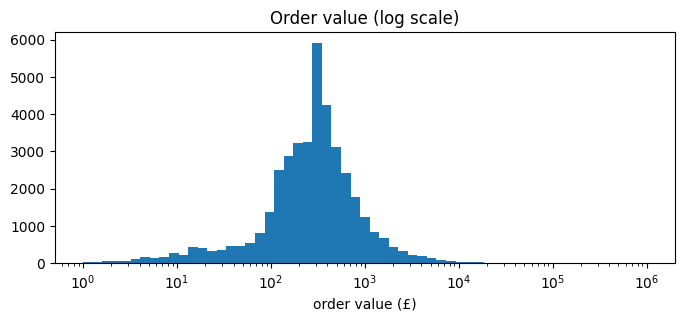

In [30]:
bins = np.logspace(0, 6, 60)

fig_hist, ax_hist = plt.subplots(figsize=(8, 3))
ax_hist.hist(orders, bins=bins)
ax_hist.set_xscale("log")
ax_hist.set_title("Order value (log scale)")
ax_hist.set_xlabel("order value (£)")
plt.show()

> 📊 **Reading the log histogram.** Now the shape appears: a hump centered on a few hundred
> pounds — the typical order a small shop places — a long thin tail of large orders out to six
> figures, and a scatter of very small ones. Same data as before; only the scale changed.

> 💡 **Transfer:** incomes, city populations, website visits per page, file sizes — many
> real quantities are "a lot of small values and a few enormous ones". For all of them, a log
> scale (and the median rather than the mean) tells the typical story.

## Revenue By Country

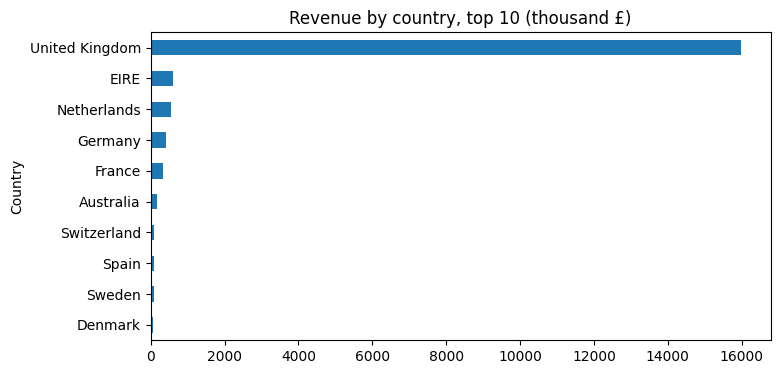

UK share of all revenue: 84.8%


In [31]:
revenue_by_country = df.groupby("Country")["Revenue"].sum()
top_countries = revenue_by_country.nlargest(10) / 1000

top_countries.sort_values().plot(kind="barh", figsize=(8, 4), title="Revenue by country, top 10 (thousand £)")
plt.show()
print(f"UK share of all revenue: {revenue_by_country['United Kingdom'] / revenue_by_country.sum():.1%}")

> 📊 **Reading the countries.** One bar dwarfs the rest: the **United Kingdom** brings
> **84.8 %** of all revenue. Ireland (`EIRE`, its Irish name, as the data writes it), the
> Netherlands, Germany and France follow, each far behind. For the manager, "the shop sells
> across Europe and beyond" and
> "the shop is a UK business with some export customers" are both true — the chart shows
> which one to lead with.

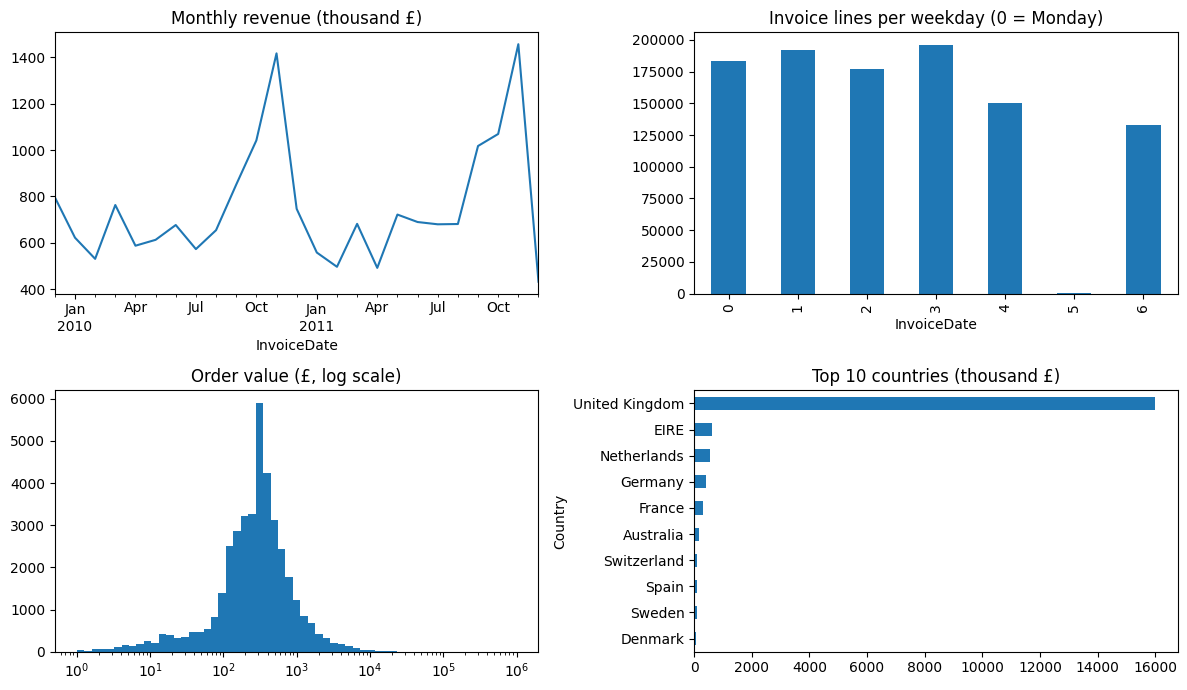

In [32]:
fig_dash, axes = plt.subplots(2, 2, figsize=(12, 7))

(monthly_revenue / 1000).plot(ax=axes[0, 0], title="Monthly revenue (thousand £)")
weekday_lines.plot(kind="bar", ax=axes[0, 1], title="Invoice lines per weekday (0 = Monday)")
axes[1, 0].hist(orders, bins=bins)
axes[1, 0].set_xscale("log")
axes[1, 0].set_title("Order value (£, log scale)")
top_countries.sort_values().plot(kind="barh", ax=axes[1, 1], title="Top 10 countries (thousand £)")

fig_dash.tight_layout()
plt.show()

> 📊 **Reading the dashboard.** The four explorations side by side: the seasonal line, the
> weekday bars, the order-value hump on a log scale and the UK-dominated countries.
> `tight_layout()` adjusted the spacing so titles and labels do not overlap. Three panels were
> drawn by pandas, one by matplotlib directly — on the same Figure.

In [34]:
df.to_parquet("retail-lines.parquet")

check = pd.read_parquet("retail-lines.parquet")
print(check.shape)

(1033036, 9)
